# Spectral (FFT) Gridding: Cost, Resolution and What You Get For It

**`radar-palette` · ARM BNF C-SAPR2 · 8 August 2026**

---

A radar volume samples a set of curved cones, not a Cartesian box. Turning one into a
3-D grid is therefore an interpolation problem with a choice of operator:

| `method=` | What it does |
| --- | --- |
| `"pyart"` | Barnes-weighted objective analysis — a distance-weighted **average** of nearby gates |
| `"spectral"` | Band-limited evaluation of each sweep on its own cone, then vertical assembly |

The average cannot exceed its inputs, so it is safe but smooths. The spectral operator
is exact where the sampling supports it, but a band-limited interpolant rings at a
discontinuity.

This notebook measures the **cost** of that choice across a resolution ramp on **two
domains**, and shows what the two operators produce at the same resolution.

| Domain | Extent | Why |
| --- | --- | --- |
| zoom | 60 x 60 km on the convective core | matches the advection notebooks; the analysis case |
| full | largest square inscribed in the radar circle, $2R/\sqrt{2}$ | spans enough cells to expose the true scaling |

Both are needed. The zoom domain is too small to load either method, and reading the
scaling from it alone would give the wrong answer -- as shown below.

## 1. Volume and region

Same case as the advection notebooks, and the same 60 × 60 km window on the convective
core so the three are directly comparable.

In [1]:
# radar-palette is not on PyPI yet:
#   pip install git+https://github.com/DIGR-Legacy/radar-palette.git

import os
import time

import numpy as np
import pandas as pd
import pyart

from radar_palette.gridding import grid_volume

LOCAL = "/Users/scollis/data/REAL/bnf_advection/case_20260808_1755"
DATADIR = LOCAL if os.path.isdir(LOCAL) else "data"
VOLUME = os.path.join(DATADIR, "bnfcsapr2cfrS3.a1.20260808.175537.nc")

radar = pyart.io.read(VOLUME)
print(f"{radar.nsweeps} sweeps, {radar.nrays} rays, {radar.ngates} gates")
print(f"elevations {radar.fixed_angle['data'].min():.1f} to "
      f"{radar.fixed_angle['data'].max():.1f} deg, "
      f"max range {radar.range['data'][-1] / 1e3:.0f} km")

# Centre the window on the >40 dBZ core of the lowest sweep.
sweep0 = np.ma.filled(radar.fields["reflectivity"]["data"].astype(float), np.nan)[
    radar.get_slice(0)]
gate_x, gate_y, _ = radar.get_gate_x_y_z(0)
core = np.isfinite(sweep0) & (sweep0 > 40)
CX, CY = float(np.mean(gate_x[core])), float(np.mean(gate_y[core]))
HALF = 30_000.0
print(f"\ncore centre {CX / 1e3:+.1f}, {CY / 1e3:+.1f} km from radar "
      f"({int(core.sum())} gates > 40 dBZ)")

# Two domains. The full one is the largest square that fits inside the radar circle:
# half-width R/sqrt(2), so its corners land exactly on the maximum range ring.
R_MAX = float(radar.range["data"][-1])
FULL_HALF = R_MAX / np.sqrt(2)

DOMAINS = {
    "zoom": {"cx": CX, "cy": CY, "half": HALF},
    "full": {"cx": 0.0, "cy": 0.0, "half": FULL_HALF},
}
for name, d in DOMAINS.items():
    print(f"{name:5s} {2 * d['half'] / 1e3:6.1f} km square, centred "
          f"({d['cx'] / 1e3:+6.1f}, {d['cy'] / 1e3:+5.1f}) km")
print(f"\nmax range {R_MAX / 1e3:.1f} km; full-domain corner at "
      f"{np.hypot(FULL_HALF, FULL_HALF) / 1e3:.1f} km")

15 sweeps, 13953 rays, 1050 gates
elevations 1.5 to 42.0 deg, max range 113 km

core centre -22.7, -2.0 km from radar (8870 gates > 40 dBZ)
zoom    60.0 km square, centred ( -22.7,  -2.0) km
full   160.3 km square, centred (  +0.0,  +0.0) km

max range 113.3 km; full-domain corner at 113.3 km


## 2. Echo top sets the grid top

Gridding to a fixed height either wastes cells on empty air or truncates the storm. A
coarse scout grid — 1 km vertical, a couple of seconds — answers it from the data.

The criterion matters. Taking the highest level with *any* echo picks up sidelobe
contamination; requiring a minimum number of cells does not.

In [2]:
BARNES_KW = dict(fields=["reflectivity"], weighting_function="Barnes2",
                 roi_func="dist_beam", min_radius=1000.0)
SPECTRAL_KW = dict(field_name="reflectivity")
MIN_CELLS = 25
Z_BOT = 500.0

def echo_top_for(domain, verbose=False):
    """Grid top from a coarse scout: highest level holding a robust amount of echo."""
    started = time.time()
    scout = grid_volume(
        radar, grid_shape=(16, 81, 81),
        grid_limits=((500., 16_000.),
                     (domain["cy"] - domain["half"], domain["cy"] + domain["half"]),
                     (domain["cx"] - domain["half"], domain["cx"] + domain["half"])),
        method="pyart", **BARNES_KW)
    values = np.ma.filled(scout.fields["reflectivity"]["data"].astype(float), np.nan)
    levels = scout.z["data"]
    counts = [int(np.nansum(values[i] > 10)) for i in range(len(levels))]
    if verbose:
        for height, n in zip(levels, counts):
            print(f"    {height / 1e3:5.1f} km  {n:6d} cells > 10 dBZ")
    robust = max(h for h, n in zip(levels, counts) if n >= MIN_CELLS)
    loose = max(h for h, n in zip(levels, counts) if n > 0)
    return robust, loose, time.time() - started

for name, domain in DOMAINS.items():
    robust, loose, elapsed = echo_top_for(domain, verbose=(name == "zoom"))
    domain["z_top"] = robust + 2000.0
    domain["limits"] = ((Z_BOT, domain["z_top"]),
                        (domain["cy"] - domain["half"], domain["cy"] + domain["half"]),
                        (domain["cx"] - domain["half"], domain["cx"] + domain["half"]))
    print(f"\n{name:5s} scout {elapsed:.1f} s | echo top >= {MIN_CELLS} cells: "
          f"{robust / 1e3:.1f} km | any cell: {loose / 1e3:.1f} km (sidelobe)")
    print(f"      grid {Z_BOT / 1e3:.1f} to {domain['z_top'] / 1e3:.1f} km")

      0.5 km    1919 cells > 10 dBZ
      1.5 km    2573 cells > 10 dBZ
      2.6 km    2766 cells > 10 dBZ
      3.6 km    2838 cells > 10 dBZ
      4.6 km    2417 cells > 10 dBZ
      5.7 km    1816 cells > 10 dBZ
      6.7 km    1563 cells > 10 dBZ
      7.7 km    1402 cells > 10 dBZ
      8.8 km    1189 cells > 10 dBZ
      9.8 km     871 cells > 10 dBZ
     10.8 km     413 cells > 10 dBZ
     11.9 km     173 cells > 10 dBZ
     12.9 km      39 cells > 10 dBZ
     13.9 km       9 cells > 10 dBZ
     15.0 km       9 cells > 10 dBZ
     16.0 km       0 cells > 10 dBZ

zoom  scout 2.3 s | echo top >= 25 cells: 12.9 km | any cell: 15.0 km (sidelobe)
      grid 0.5 to 14.9 km

full  scout 2.0 s | echo top >= 25 cells: 11.9 km | any cell: 15.0 km (sidelobe)
      grid 0.5 to 13.9 km


## 3. The resolution ramp

Ten steps from 2000 m to 250 m, isotropic, both methods, **both domains**. On the zoom
domain the cell count spans about 400x; on the full domain it reaches 22 million.

This takes several minutes.


In [3]:
def grid_shape_for(domain, resolution_m):
    """Isotropic lattice covering the domain at the given resolution."""
    nz = int(round((domain["z_top"] - Z_BOT) / resolution_m)) + 1
    ny = nx = int(round(2 * domain["half"] / resolution_m)) + 1
    return nz, ny, nx

import gc

def time_grid(method, shape, limits):
    kwargs = BARNES_KW if method == "pyart" else SPECTRAL_KW
    started = time.time()
    grid = grid_volume(radar, grid_shape=shape, grid_limits=limits,
                       method=method, **kwargs)
    elapsed = time.time() - started
    values = np.ma.filled(grid.fields["reflectivity"]["data"].astype(float), np.nan)
    filled = float(np.isfinite(values).mean())
    peak = float(np.nanmax(values)) if np.isfinite(values).any() else np.nan
    del grid, values
    # Release before timing the next step. Without this the previous grid is still
    # resident when the largest one allocates, and the 200 m Barnes step reads 883 s
    # against a true 92 s -- a memory-pressure artefact, not algorithmic cost.
    gc.collect()
    return elapsed, filled, peak

RESOLUTIONS = np.linspace(2000.0, 250.0, 10)
# The full domain gets one extra, finer point: at 250 m the two methods are within
# 15% of each other, so a single step past the crossover settles which side it lands on.
EXTRA_FULL = [200.0]

records = []
for name, domain in DOMAINS.items():
    # One untimed call per method: the first invocation pays import and cache costs
    # that would otherwise appear as a spurious bump at the coarse end.
    for method in ("pyart", "spectral"):
        time_grid(method, grid_shape_for(domain, 2000.0), domain["limits"])
    print(f"--- {name} domain, {2 * domain['half'] / 1e3:.0f} km square ---")
    steps = list(RESOLUTIONS) + (EXTRA_FULL if name == "full" else [])
    for resolution in steps:
        shape = grid_shape_for(domain, resolution)
        row = {"domain": name, "res_m": resolution, "cells": int(np.prod(shape)),
               "nz": shape[0], "ny": shape[1], "nx": shape[2]}
        for method in ("pyart", "spectral"):
            row[f"{method}_s"], row[f"{method}_filled"], row[f"{method}_max"] = \
                time_grid(method, shape, domain["limits"])
        records.append(row)
        print(f"  {resolution:6.0f} m {row['cells']:11,d} cells   "
              f"barnes {row['pyart_s']:6.2f} s   spectral {row['spectral_s']:6.2f} s")

ramp = pd.DataFrame(records)

--- zoom domain, 60 km square ---
    2000 m       7,688 cells   barnes   1.52 s   spectral  36.59 s
    1806 m      10,404 cells   barnes   1.53 s   spectral  36.35 s
    1611 m      14,440 cells   barnes   1.55 s   spectral  37.05 s
    1417 m      20,339 cells   barnes   1.55 s   spectral  37.87 s
    1222 m      32,500 cells   barnes   1.56 s   spectral  37.28 s
    1028 m      52,215 cells   barnes   1.62 s   spectral  37.23 s
     833 m      95,922 cells   barnes   1.63 s   spectral  37.98 s
     639 m     216,600 cells   barnes   1.77 s   spectral  38.34 s
     444 m     610,368 cells   barnes   2.14 s   spectral  38.12 s
     250 m   3,426,779 cells   barnes   4.45 s   spectral  38.94 s
--- full domain, 160 km square ---
    2000 m      52,488 cells   barnes   1.86 s   spectral  38.09 s
    1806 m      64,800 cells   barnes   1.89 s   spectral  37.99 s
    1611 m      90,000 cells   barnes   1.95 s   spectral  38.31 s
    1417 m     129,960 cells   barnes   2.06 s   spectral  3

## 4. Scaling: the domain you test on changes the answer

The naive expectation is that both methods scale with the number of output cells.
Measured on the zoom domain alone you would conclude that neither does -- and for Barnes
that conclusion is an artefact of too small a domain.


In [4]:
for name in DOMAINS:
    sub = ramp[ramp.domain == name]
    span = sub.cells.iloc[-1] / sub.cells.iloc[0]
    print(f"--- {name} domain: {sub.cells.iloc[0]:,d} to {sub.cells.iloc[-1]:,d} cells "
          f"({span:.0f}x) ---")
    for method in ("pyart", "spectral"):
        t = sub[f"{method}_s"]
        exponent = np.polyfit(np.log(sub.cells), np.log(t), 1)[0]
        print(f"  {method:9s} {t.iloc[0]:6.2f} -> {t.iloc[-1]:6.2f} s "
              f"({t.iloc[-1] / t.iloc[0]:5.1f}x)   mean d(log t)/d(log cells) = {exponent:+.3f}")
    print()

# Barnes is convex in log-log, so a single exponent understates the fine end.
sub = ramp[ramp.domain == "full"]
local = [np.log(sub.pyart_s.iloc[k + 1] / sub.pyart_s.iloc[k]) /
         np.log(sub.cells.iloc[k + 1] / sub.cells.iloc[k]) for k in range(len(sub) - 1)]
print("Barnes local exponent per segment, full domain (coarse -> fine):")
print("  " + "  ".join(f"{v:.2f}" for v in local))

--- zoom domain: 7,688 to 3,426,779 cells (446x) ---
  pyart       1.52 ->   4.45 s (  2.9x)   mean d(log t)/d(log cells) = +0.148
  spectral   36.59 ->  38.94 s (  1.1x)   mean d(log t)/d(log cells) = +0.010

--- full domain: 52,488 to 43,737,872 cells (833x) ---
  pyart       1.86 ->  91.88 s ( 49.4x)   mean d(log t)/d(log cells) = +0.575
  spectral   38.09 ->  47.81 s (  1.3x)   mean d(log t)/d(log cells) = +0.027

Barnes local exponent per segment, full domain (coarse -> fine):
  0.09  0.09  0.15  0.18  0.26  0.37  0.54  0.74  0.89  0.93


Two readings, and they differ.

On the **zoom** domain Barnes looks nearly flat, a mean exponent of 0.148, and it is
easy to conclude that neither method cares about the lattice. On the **full** domain the
mean is 0.575 and the local exponent climbs monotonically from 0.09 at the coarse end to
0.93 at the fine end. Barnes is asymptotically per-cell; it simply carries enough fixed
overhead that a small domain never reaches the asymptote.

The spectral path stays nearly flat on both -- 0.010 and 0.027 -- across cell counts
spanning 446x and 833x. That is a statement about where its work happens, and it is
testable: hold the lattice fixed and halve the *input* instead.


In [5]:
subset = radar.extract_sweeps(list(range(0, radar.nsweeps, 2)))
shape = grid_shape_for(DOMAINS["full"], 833.0)
limits = DOMAINS["full"]["limits"]

for label, volume in (("all sweeps", radar), ("every other sweep", subset)):
    started = time.time()
    grid = grid_volume(volume, grid_shape=shape, grid_limits=limits,
                       method="spectral", **SPECTRAL_KW)
    elapsed = time.time() - started
    print(f"  {label:18s} {volume.nsweeps:2d} sweeps, {volume.nrays:5d} rays "
          f"-> {elapsed:5.2f} s")
    del grid

  all sweeps         15 sweeps, 13953 rays -> 37.82 s
  every other sweep   8 sweeps,  7441 rays -> 19.96 s


Roughly half the rays, roughly half the time, with the output lattice unchanged. The
cost is in **building one band-limited evaluator per sweep** -- a decomposition of the
measured rays -- and evaluating that operator at however many lattice points you ask for
is comparatively cheap.

So the two methods are limited by different things, and on the full domain they actually
**cross over**: Barnes is an order of magnitude faster at 2 km, and slower than the
spectral path by 250 m. Choose on the resolution and domain you need, not on a general
claim about which is faster.


### Where they cross

Worth locating from the measurements rather than extrapolating a fitted power law --
Barnes is convex in log-log, so a single exponent would put the crossover in the wrong
place by a wide margin.

In [6]:
sub = ramp[ramp.domain == "full"].reset_index(drop=True)
sub = sub.assign(ratio=sub.spectral_s / sub.pyart_s)
print(sub[["res_m", "cells", "pyart_s", "spectral_s", "ratio"]].to_string(
    index=False, float_format=lambda v: f"{v:.2f}"))

faster = sub[sub.ratio < 1]
if len(faster) and len(faster) < len(sub):
    k = int(faster.index[0])
    lo, hi = sub.iloc[k - 1], sub.iloc[k]
    weight = np.log(lo.ratio) / (np.log(lo.ratio) - np.log(hi.ratio))
    crossover = np.exp(np.log(lo.cells) + weight * np.log(hi.cells / lo.cells))
    print(f"\nratio crosses 1 between {lo.cells:,d} and {hi.cells:,d} cells")
    print(f"log-interpolated crossover: {crossover:,.0f} cells")
else:
    print("\nno crossover within the sampled range")


  res_m    cells  pyart_s  spectral_s  ratio
2000.00    52488     1.86       38.09  20.49
1805.56    64800     1.89       37.99  20.07
1611.11    90000     1.95       38.31  19.63
1416.67   129960     2.06       37.77  18.33
1222.22   209088     2.24       37.95  16.93
1027.78   345086     2.56       39.29  15.35
 833.33   633233     3.20       39.45  12.33
 638.89  1397088     4.91       37.76   7.69
 444.44  4062364    10.80       39.27   3.64
 250.00 22256856    48.86       43.61   0.89
 200.00 43737872    91.88       47.81   0.52

ratio crosses 1 between 4,062,364 and 22,256,856 cells
log-interpolated crossover: 19,394,729 cells


## 5. Performance plot

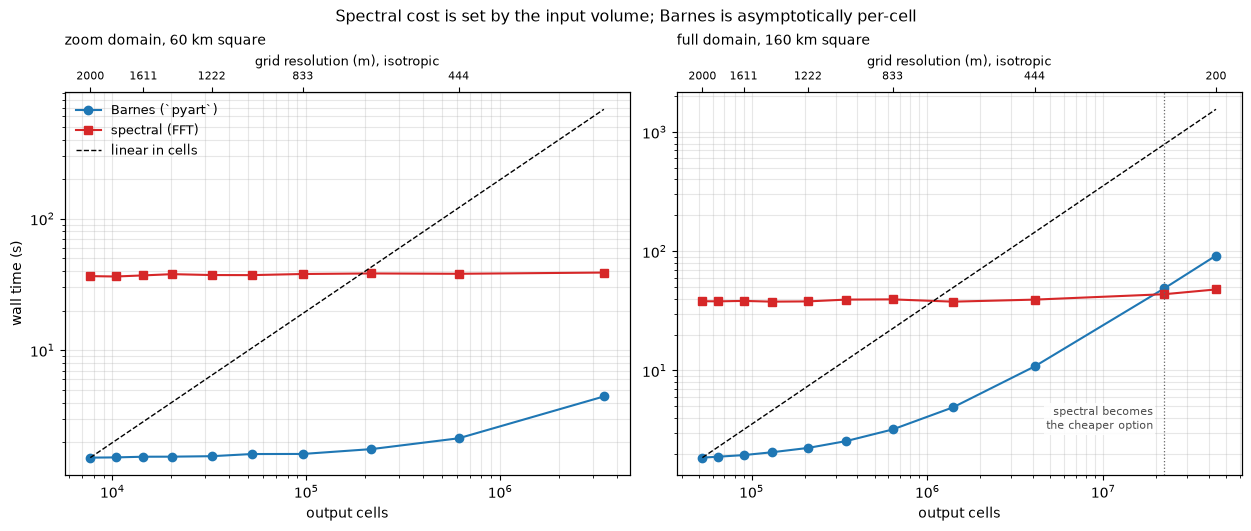

In [7]:
import matplotlib.pyplot as plt

STYLE = {"pyart": ("#1f77b4", "o", "Barnes (`pyart`)"),
         "spectral": ("#d62728", "s", "spectral (FFT)")}

def resolution_axis(ax, sub, every=2):
    """Second x axis labelled in resolution.

    Ticks sit at the MEASURED cell counts rather than at a closed-form inversion of
    resolution: each axis length is round(span / res) + 1, so the smooth formula
    span_z * span_h**2 / res**3 is off by up to 22% at the coarse end.
    """
    top = ax.twiny()
    top.set_xscale("log")
    top.set_xlim(ax.get_xlim())
    shown = sub.iloc[::every]
    top.set_xticks(list(shown.cells))
    top.set_xticklabels([f"{r:.0f}" for r in shown.res_m], fontsize=8)
    top.set_xlabel("grid resolution (m), isotropic", fontsize=9)
    top.tick_params(axis="x", which="minor", top=False)
    return top

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.2), constrained_layout=True)
for ax, name in zip(axes, DOMAINS):
    sub = ramp[ramp.domain == name].sort_values("cells")
    for method, (colour, marker, label) in STYLE.items():
        ax.plot(sub.cells, sub[f"{method}_s"], marker=marker, color=colour,
                ls="-", label=label)
    reference = sub.pyart_s.iloc[0] * sub.cells / sub.cells.iloc[0]
    ax.plot(sub.cells, reference, "k--", lw=1, label="linear in cells")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("output cells")
    ax.grid(alpha=0.3, which="both")
    resolution_axis(ax, sub)
    side_km = 2 * DOMAINS[name]["half"] / 1e3
    ax.set_title(f"{name} domain, {side_km:.0f} km square", fontsize=10, loc="left",
                 pad=34)

axes[0].set_ylabel("wall time (s)")
axes[0].legend(frameon=False, fontsize=9, loc="upper left")

sub = ramp[ramp.domain == "full"].sort_values("cells")
crossing = sub[sub.spectral_s < sub.pyart_s]
if len(crossing):
    axes[1].axvline(crossing.cells.iloc[0], color="0.4", lw=0.9, ls=":")
    axes[1].annotate("spectral becomes\nthe cheaper option",
                     xy=(crossing.cells.iloc[0], sub.pyart_s.min()),
                     xytext=(-8, 18), textcoords="offset points",
                     ha="right", va="bottom", fontsize=8, color="0.3",
                     bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))

fig.suptitle("Spectral cost is set by the input volume; Barnes is asymptotically "
             "per-cell", fontsize=11.5)
fig.savefig("figures/gridding_performance.png", dpi=130)

The dashed line is proportionality to cell count. On the zoom domain both traces sit far
below it and the two look like different kinds of algorithm. On the full domain the
Barnes trace bends up to run parallel with it at the fine end, while the spectral trace
stays flat -- and they cross.


## 6. What the two produce

Same volume, same extent, at 1500 m and 500 m -- on **both** domains. The zoom panels
show the storm structure; the full-domain panels show what the two operators do to a
whole scan, including the regions between cones far from the radar.

Slice indices come from the data in each domain separately -- the level with the most
echo above 30 dBZ, and the row through it -- rather than being fixed by hand.


In [8]:
def slice_grids(domain, resolutions=(1500.0, 500.0)):
    """Grid the domain with both methods at each resolution, keeping the arrays."""
    out = {}
    for resolution in resolutions:
        shape = grid_shape_for(domain, resolution)
        entry = {"shape": shape}
        for method in ("pyart", "spectral"):
            kwargs = BARNES_KW if method == "pyart" else SPECTRAL_KW
            started = time.time()
            grid = grid_volume(radar, grid_shape=shape, grid_limits=domain["limits"],
                               method=method, **kwargs)
            entry[method] = {
                "z": np.ma.filled(grid.fields["reflectivity"]["data"].astype(float),
                                  np.nan),
                "x": grid.x["data"].copy(), "y": grid.y["data"].copy(),
                "levels": grid.z["data"].copy(), "t": time.time() - started}
            del grid
        out[resolution] = entry
        print(f"  {resolution:6.0f} m {str(shape):18s} "
              f"barnes {entry['pyart']['t']:5.2f} s   "
              f"spectral {entry['spectral']['t']:6.2f} s")
    return out

def slice_targets(entry):
    """Level with the most echo above 30 dBZ, and the row through it."""
    values = entry["pyart"]["z"]
    k = int(np.argmax([np.nansum(values[i] > 30) for i in range(values.shape[0])]))
    j = int(np.argmax(np.nansum(np.nan_to_num(values[k] > 30), axis=1)))
    return entry["pyart"]["levels"][k], entry["pyart"]["y"][j]

SLICES = {}
for name, domain in DOMAINS.items():
    print(f"--- {name} domain ---")
    SLICES[name] = slice_grids(domain)
    z_t, y_t = slice_targets(SLICES[name][500.0])
    DOMAINS[name]["z_target"], DOMAINS[name]["y_target"] = z_t, y_t
    print(f"  slices at z = {z_t / 1e3:.2f} km, y = {y_t / 1e3:+.2f} km\n")

--- zoom domain ---
    1500 m (11, 41, 41)       barnes  1.56 s   spectral  36.58 s
     500 m (30, 121, 121)     barnes  1.95 s   spectral  36.39 s
  slices at z = 1.99 km, y = -3.54 km

--- full domain ---
    1500 m (10, 108, 108)     barnes  2.02 s   spectral  36.34 s
     500 m (28, 322, 322)     barnes  8.04 s   spectral  37.25 s
  slices at z = 2.48 km, y = -3.75 km



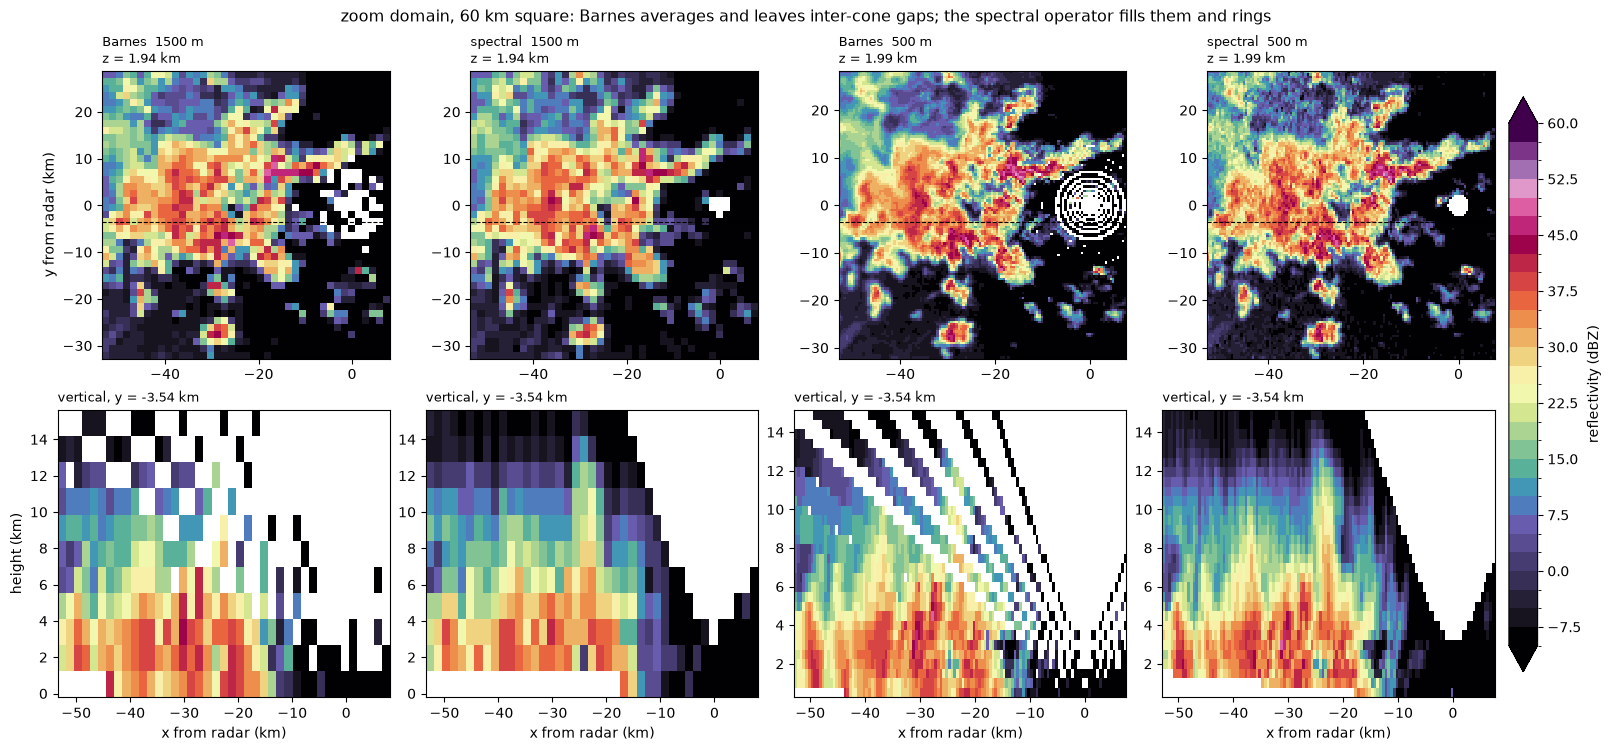

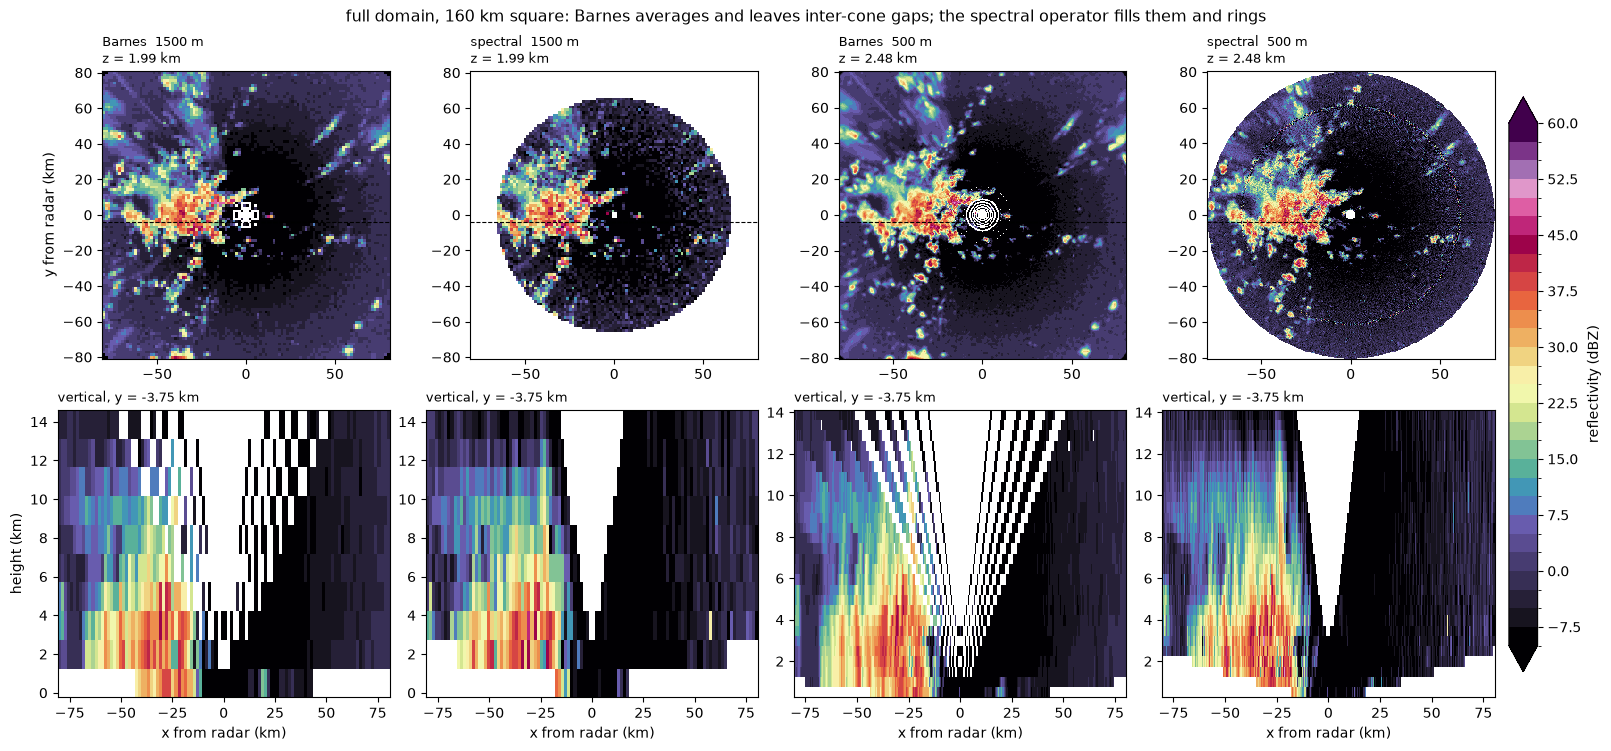

In [9]:
from matplotlib.colors import BoundaryNorm

LEVELS = np.arange(-10, 62, 2.5)
NORM = BoundaryNorm(LEVELS, 256)

def nearest(axis, value):
    return int(np.argmin(np.abs(axis - value)))

def slice_figure(name, filename):
    """Horizontal and vertical slices, both methods, two resolutions."""
    domain = DOMAINS[name]
    z_target, y_target = domain["z_target"], domain["y_target"]
    entries = SLICES[name]

    fig, axes = plt.subplots(2, 4, figsize=(16, 7.4), constrained_layout=True)
    for col, (resolution, method) in enumerate(
            [(1500.0, "pyart"), (1500.0, "spectral"),
             (500.0, "pyart"), (500.0, "spectral")]):
        entry = entries[resolution][method]
        x_km, y_km, z_km = entry["x"] / 1e3, entry["y"] / 1e3, entry["levels"] / 1e3
        k = nearest(entry["levels"], z_target)
        j = nearest(entry["y"], y_target)

        ax = axes[0, col]
        mesh = ax.pcolormesh(x_km, y_km, np.ma.masked_invalid(entry["z"][k]),
                             cmap="ChaseSpectral", norm=NORM, shading="nearest")
        ax.axhline(entry["y"][j] / 1e3, color="k", lw=0.8, ls="--")
        ax.set_aspect("equal")
        ax.set_title(f"{'Barnes' if method == 'pyart' else 'spectral'}  "
                     f"{resolution:.0f} m\nz = {z_km[k]:.2f} km",
                     fontsize=9.5, loc="left")
        if col == 0:
            ax.set_ylabel("y from radar (km)")

        ax = axes[1, col]
        ax.pcolormesh(x_km, z_km, np.ma.masked_invalid(entry["z"][:, j, :]),
                      cmap="ChaseSpectral", norm=NORM, shading="nearest")
        ax.set_xlabel("x from radar (km)")
        ax.set_title(f"vertical, y = {y_km[j]:+.2f} km", fontsize=9.5, loc="left")
        if col == 0:
            ax.set_ylabel("height (km)")

    side_km = 2 * domain["half"] / 1e3
    fig.colorbar(mesh, ax=axes, extend="both", fraction=0.02, pad=0.01,
                 label="reflectivity (dBZ)")
    fig.suptitle(f"{name} domain, {side_km:.0f} km square: Barnes averages and leaves "
                 f"inter-cone gaps; the spectral operator fills them and rings",
                 fontsize=11.5)
    fig.savefig(filename, dpi=130)
    return fig

slice_figure("zoom", "figures/gridding_slices_zoom.png")
slice_figure("full", "figures/gridding_slices_full.png")

## 7. Where the two genuinely differ: inter-cone gaps

The vertical slices show it plainly, and the full domain shows it worse. A radar samples
discrete cones, and between them there is no data. Barnes needs gates inside a radius of
influence, so above the height where neighbouring cones separate it returns holes -- the
striping in the Barnes panels, which widens with range. Vertical assembly interpolates
*along each column between the cones it has*, so it fills them.

Worth counting rather than eyeballing: an interior hole is a NaN with valid data both
above and below it in the same column.


In [10]:
def interior_holes(section):
    """NaN cells with valid data both above and below them in the same column."""
    total = 0
    for column in range(section.shape[1]):
        finite = np.isfinite(section[:, column])
        if finite.sum() < 2:
            continue
        low = int(np.argmax(finite))
        high = len(finite) - 1 - int(np.argmax(finite[::-1]))
        total += int((~finite[low:high + 1]).sum())
    return total

for name, domain in DOMAINS.items():
    entry = SLICES[name][500.0]
    j = nearest(entry["pyart"]["y"], domain["y_target"])
    print(f"--- {name} domain, 500 m ---")
    for method in ("pyart", "spectral"):
        section = entry[method]["z"][:, j, :]
        levels = entry[method]["levels"]
        aloft = levels > 4000
        per_level = np.array([np.isfinite(section[i]).mean()
                              for i in range(len(levels))])
        print(f"  {method:9s} slice filled {np.isfinite(section).mean():6.1%}   "
              f"above 4 km, per-level fill spans "
              f"{per_level[aloft].min():5.1%}-{per_level[aloft].max():5.1%}   "
              f"interior holes: {interior_holes(section):5d}")

--- zoom domain, 500 m ---
  pyart     slice filled  55.8%   above 4 km, per-level fill spans 23.1%-70.2%   interior holes:   686
  spectral  slice filled  76.0%   above 4 km, per-level fill spans 61.2%-88.4%   interior holes:     0
--- full domain, 500 m ---
  pyart     slice filled  75.0%   above 4 km, per-level fill spans 54.0%-86.3%   interior holes:  1106
  spectral  slice filled  84.8%   above 4 km, per-level fill spans 81.4%-96.3%   interior holes:     0


Zero interior holes against several hundred. That is the clearest practical argument for
the spectral path: if the next step is a vertical integral, a gradient, or anything that
reads a column, holes between the cones are not a cosmetic problem.

The cost is stated honestly in the ringing above — a band-limited interpolant overshoots
at a sharp edge where an average cannot.

## 8. Range, coverage, and a caveat that only the full domain exposes

An average cannot exceed its inputs; a band-limited interpolant can. On the zoom domain
that shows up as a few dB of overshoot. On the full domain it is far worse in a small
number of cells -- and worth knowing about before you trust a domain-wide statistic.


In [11]:
observed = np.ma.filled(radar.fields["reflectivity"]["data"].astype(float), np.nan)
print(f"observed gates: min {np.nanmin(observed):6.1f}  "
      f"max {np.nanmax(observed):6.1f} dBZ\n")

print(f"{'domain':6s} {'res':>6}  {'method':9s} {'min':>7} {'max':>7} "
      f"{'filled':>7} {'>50 dBZ':>8}")
for name in DOMAINS:
    for resolution in (1500.0, 500.0):
        for method in ("pyart", "spectral"):
            values = SLICES[name][resolution][method]["z"]
            print(f"{name:6s} {resolution:6.0f}  {method:9s} "
                  f"{np.nanmin(values):7.1f} {np.nanmax(values):7.1f} "
                  f"{np.isfinite(values).mean():7.1%} "
                  f"{int(np.nansum(values > 50)):8d}")

observed gates: min  -80.0  max   68.0 dBZ

domain    res  method        min     max  filled  >50 dBZ
zoom     1500  pyart       -46.0    55.2   66.9%        8
zoom     1500  spectral    -52.2    53.1   85.7%        2
zoom      500  pyart       -80.0    63.3   68.1%      279
zoom      500  spectral    -61.1    66.5   88.8%      320
full     1500  pyart       -80.0    55.7   84.8%       16
full     1500  spectral   -142.8   159.7   83.9%       40
full      500  pyart       -80.0    61.8   88.7%      281
full      500  spectral   -202.6   270.0   87.0%     1190


Two things to read off. The spectral path fills **more** of the domain, because it
evaluates each sweep as a continuous function on its cone rather than requiring gates
within a radius of influence. And it can overshoot the observed range at a sharp edge,
which the average cannot by construction.

Neither is a defect. They are the two sides of the same property, and which one you want
depends on whether you are about to compute a gradient or a domain mean.

The spectral path produces values outside anything physical -- hundreds of dBZ -- in a
tiny fraction of cells. They sit **inside** the coverage disc, not at the corners, so
this is interpolant ringing where the sampling is marginal, not an edge-of-domain
artefact. The zoom domain contains none of them, which is precisely why it is worth
running the wider test.

The practical response is to clip or mask on a physical ceiling before using a spectral
grid for anything aggregated. The count is small enough that it will not move a mean,
and large enough that it will destroy a maximum.

In [12]:
CEILING = 80.0  # dBZ; nothing meteorological approaches this

print(f"{'domain':6s} {'res':>6}  cells |Z| > {CEILING:.0f} dBZ    "
      f"fraction      where\n")
for name in DOMAINS:
    for resolution in (1500.0, 500.0):
        entry = SLICES[name][resolution]["spectral"]
        values = entry["z"]
        extreme = np.abs(values) > CEILING
        if extreme.any():
            _, j_idx, i_idx = np.where(extreme)
            ranges = np.hypot(entry["x"][i_idx], entry["y"][j_idx]) / 1e3
            where = f"{ranges.min():.0f}-{ranges.max():.0f} km from radar"
        else:
            where = "-"
        print(f"{name:6s} {resolution:6.0f}  {int(extreme.sum()):11d}        "
              f"{extreme.mean():9.4%}   {where}")

print(f"\nradar maximum range: {radar.range['data'][-1] / 1e3:.1f} km")


domain    res  cells |Z| > 80 dBZ    fraction      where

zoom     1500            0          0.0000%   -
zoom      500            0          0.0000%   -
full     1500           12          0.0103%   61-92 km from radar
full      500          631          0.0217%   26-99 km from radar

radar maximum range: 113.3 km


## Summary

- **Test scaling on a domain large enough to reach the asymptote.** On a 60 km box
  Barnes looks lattice-insensitive (mean exponent 0.148); on the full inscribed square its
  local exponent climbs to 0.93 and it is plainly per-cell. The small domain would have
  given the wrong answer.
- **Spectral cost is set by the input volume, not the output lattice.** Nearly flat across cell
  counts spanning 446x and 833x; halving the rays halves the time. Budget on
  sweep count.
- **The two cross over.** Barnes is an order of magnitude faster at 2 km and slower by
  250 m on the full domain. Neither is simply faster.
- **Determine the grid top from the data**, with a criterion robust to sidelobe: a couple
  of seconds of scout grid avoids either truncating the storm or gridding empty air.
- **Barnes leaves holes between the cones; vertical assembly fills them.** On the 500 m
  slice: 686 interior holes on the zoom domain and 1106 on the full domain, against zero
  for the spectral path -- decisive if the next step reads a column.
- **Check a spectral grid for out-of-range values before aggregating.** A few hundred
  cells (0.02%) reach hundreds of dBZ on the full domain, inside coverage, and none on
  the zoom domain. They will not move a mean and will destroy a maximum.
- **Barnes cannot exceed its inputs; the spectral operator can.** Pick for the analysis
  that follows.


## References

- `radar-palette` — <https://github.com/DIGR-Legacy/radar-palette>
- Py-ART — Helmus & Collis (2016), *JORS* 4(1), e25, doi:10.5334/jors.119
- Barnes, S. L. (1964). A technique for maximizing details in numerical weather map
  analysis. *Journal of Applied Meteorology*, 3(4), 396–409.
- Companion notebooks:
  [Radar_Volume_Advection_Interpolation.ipynb](Radar_Volume_Advection_Interpolation.ipynb),
  [Advecting_Polarimetric_Variables_carry_fields.ipynb](Advecting_Polarimetric_Variables_carry_fields.ipynb)
